In [1]:
import pandas as pd

df = pd.read_csv(
    '/content/fintech_clean.csv',
    parse_dates=['date_received', 'date_sent_to_company']
)
print(df.shape)
df.dtypes

(162698, 15)


,0
complaint_id,int64
date_received,datetime64[ns]
date_sent_to_company,datetime64[ns]
product,object
sub_product,object
issue,object
sub_issue,object
company,object
company_clean,object
state,object


In [2]:
import numpy as np

df['segment'] = np.where(
    df['company_clean'].isin(['Block', 'Early Warning (Zelle)']),
    'Block+Zelle', 'Other 10'
)

monthly = (
    df.groupby([df['date_received'].dt.to_period('M'), 'segment'])
      .size()
      .unstack(fill_value=0)
)
monthly.head(14)

segment,Block+Zelle,Other 10
date_received,,
2024-01,277,973
2024-02,298,933
2024-03,297,1126
2024-04,305,1098
2024-05,313,1254
2024-06,313,1025
2024-07,338,1215
2024-08,475,1221
2024-09,326,1086


In [3]:
d = df[df['date_received'] < '2026-11-01'].copy()
d['period'] = np.where(d['date_received'] >= '2026-01-01', '2026 (Jan-Oct)', '2024-25 baseline')

other = d[d['segment'] == 'Other 10']

monthly_other = (
    other.groupby([other['date_received'].dt.to_period('M'), 'period'])
         .size()
         .reset_index(name='complaints')
)

monthly_other.groupby('period')['complaints'].agg(['count', 'mean', 'median'])

,count,mean,median
period,,,
2024-25 baseline,24,1683.291667,1474.5
2026 (Jan-Oct),10,3464.200000,3434.0


In [4]:
import statsmodels.formula.api as smf

ts = monthly_other.sort_values('date_received').reset_index(drop=True)
ts['t'] = range(len(ts))
ts['post'] = (ts['period'] == '2026 (Jan-Oct)').astype(int)

model = smf.ols('complaints ~ t + post', data=ts).fit(
    cov_type='HAC', cov_kwds={'maxlags': 3}
)
print(model.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    679.6939    136.768      4.970      0.000     411.634     947.754
t             87.2694     12.156      7.179      0.000      63.444     111.095
post         297.3290    235.243      1.264      0.206    -163.739     758.397


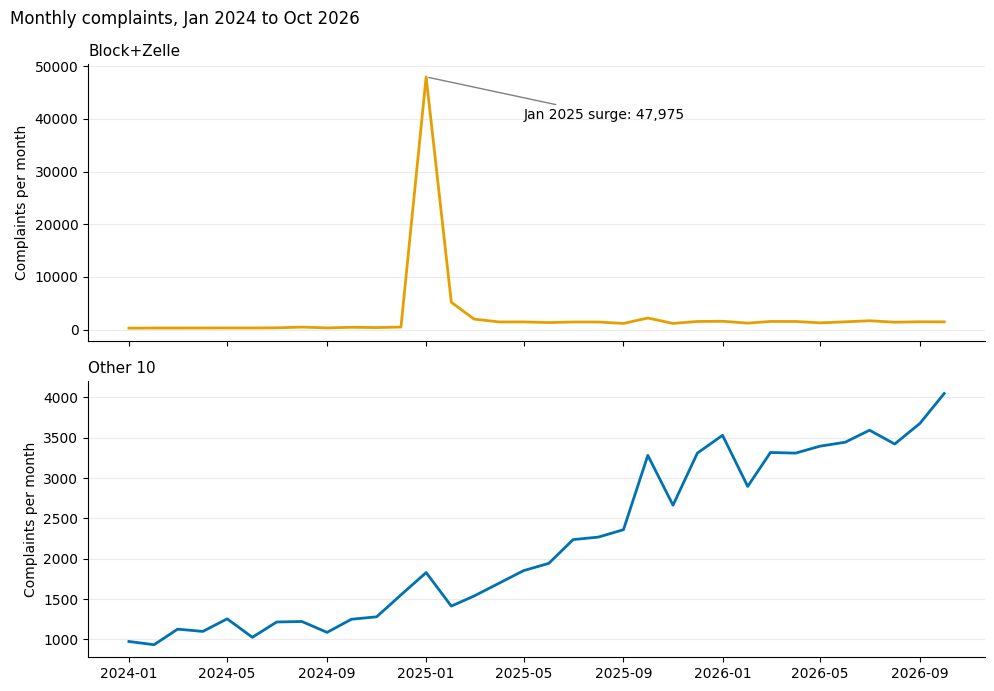

In [5]:
import matplotlib.pyplot as plt

m = monthly[monthly.index < pd.Period('2026-11', 'M')].copy()
m.index = m.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

series = [('Block+Zelle', '#E69F00'), ('Other 10', '#0072B2')]
for ax, (name, color) in zip(axes, series):
    ax.plot(m.index, m[name], color=color, linewidth=2)
    ax.set_title(name, loc='left', fontsize=11)
    ax.set_ylabel('Complaints per month')
    ax.grid(axis='y', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].annotate(
    'Jan 2025 surge: 47,975',
    xy=(pd.Timestamp('2025-01-01'), 47975),
    xytext=(pd.Timestamp('2025-05-01'), 40000),
    arrowprops=dict(arrowstyle='-', color='gray')
)

fig.suptitle('Monthly complaints, Jan 2024 to Oct 2026', x=0.01, ha='left')
plt.tight_layout()
plt.show()

In [6]:
closed = ['Closed with explanation',
          'Closed with monetary relief',
          'Closed with non-monetary relief']
relief_types = ['Closed with monetary relief',
                'Closed with non-monetary relief']

c = df[df['company_response_to_consumer'].isin(closed) &
       (df['segment'] == 'Other 10')].copy()

c['relief'] = c['company_response_to_consumer'].isin(relief_types)
c['period'] = np.where(c['date_received'] >= '2026-01-01', '2026', '2024-25')

rates = (
    c.groupby(['company_clean', 'period'])['relief']
     .mean().mul(100).round(1)
     .unstack()
)
rates.sort_values('2026', ascending=False)

period,2024-25,2026
company_clean,,
PayPal,29.2,43.0
Coinbase,23.3,40.7
Wise,9.4,13.0
Klarna,4.5,10.6
SoFi,8.0,7.8
Chime,10.5,7.2
MoneyLion,24.9,0.9
Upstart,1.0,0.8
Affirm,0.0,0.0


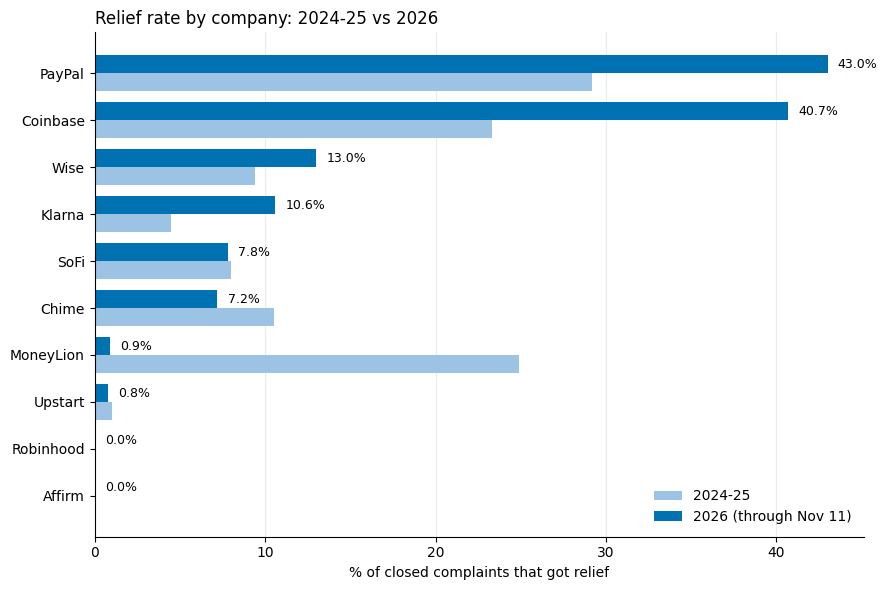

In [7]:
plot_df = rates.sort_values('2026')

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(plot_df))
h = 0.38

ax.barh(y - h/2, plot_df['2024-25'], height=h, color='#9CC3E4', label='2024-25')
ax.barh(y + h/2, plot_df['2026'], height=h, color='#0072B2', label='2026 (through Nov 11)')

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.set_xlabel('% of closed complaints that got relief')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Relief rate by company: 2024-25 vs 2026', loc='left')

for i, val in enumerate(plot_df['2026']):
    ax.text(val + 0.6, i + h/2, f'{val:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## Findings

**1. Volume trend.** Complaints about the 10 companies other than Block and Zelle grew by about 87 per month (p < 0.001). A model with a 2026 shift term finds no statistically detectable jump above that trend (+297 per month, p = 0.21, 95% CI -164 to +758), so the doubling of monthly volume in 2026 mostly reflects continued growth, not a structural break. With only 10 months of 2026 data and a straight-line trend assumption, a small shift could go undetected.

**2. Block and Zelle surge.** January 2025 had 47,975 complaints for Block and Zelle, versus roughly 300 to 500 a month in 2024. Press coverage links the surge to major enforcement news and to influencer-driven complaint campaigns (sources in `docs/data_source.md`). It is treated separately and flagged as an outlier.

**3. Relief rates.** Among the 10 companies, the share of closed complaints receiving relief was 14.5% (2024), 14.3% (2025) and 18.6% (2026). The 2026 rise is concentrated in PayPal (29.2% to 43.0%) and Coinbase (23.3% to 40.7%), while others fell (MoneyLion, Chime). Block and Zelle gave relief in under 1% of closed complaints in every year. Affirm and Robinhood record 0% relief, which likely reflects how they report outcomes.

**Limitations.** Complaints are unverified and company responses are self-reported. There are no customer counts, so rates and shares are compared, not raw volume. November 2026 is excluded as a partial month. The trend model is deliberately simple.